# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary.

---

**Determine Business Ojectives:**
- We are provided a dataset of 426 thousand cars to help our client understand what customers value in used cars.
- Analyze relationships between different features provided by the dataset and our target feature, price.
- Success would be to be able to model and analyse this data and document sufficient findings that can help our client.

**Assess Situation**
- Resources are access to a data science envoronment, in our case we are using Python with pandas, scikit-learn, and matplotlib/seaborn running on a local machine. We also have a kaggle dataset with features such as year, manufacturer, condition, and more.
- Our Assumption is that our dataset is sufficient to accurately represent the general market.
- Our risks and constraints are data quality issues, such as missing values, outliers, or extreme pricing.
- **Data Mining Terminology**:
    - *Target feature*: the primary outcome we want to explain, in our analysis, it's `price`.
    - *Feature*: an attribute used as an input for our models, such as `condition`, `mileage`, `year`, `make`, etc. 
    - *Categorical vs Numerical*: Categorical would be discrete groups such as paint color, which require encoding, whereas, numerical is quantifiable and numeric which is easier to handle.
    - *Outlier*: extreme data that would skew our data, an example would be someone selling a car for a dollar.
    - *Overfitting*: when a model is trained too well on our data, memorizing the noise in the data, making it worse on new, unseen data.
    - *coefficients*: represent the strength and direction of the relationship between each specific feature and our target variable


- We're required to deliver clear and **actionable** business recommendations and a predictive model for our client to help understand what drives consumer value, our costs are the time spent to draft a sound analysis, a small amount of compute power, and thankfully we don't have to pay for the dataset. Benefits will be providing key insights to our client.


**Determine Data Mining Goals**
- Our data mining goal is to build regression models to accurately predict the target feature, price, based on its attributes, which we can evaluate with RMSE.
- Our data mining success criteria is extracting feature coefficients to quantify how much specific features impact consumer value on used cars.

**Produce Project Plan**
- **Data understanding, data preparation, modeling, evaluation, and deployment:**
    - We will look at the data, look at all the various features, look at the different data types, and look at outliers and missing data.
    - Handle any missing values, drop/filter outliers, encode our categorical features, and engineer new features that may be useful for modeling.
    - We will establish a baseline linear model, then iterate with regression models.
    - Then we need to evaluate our model performance, find the key drivers to price, and provide actionable recommendations to our client.


### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

---

1. Inspect the dataset shape, column names, data types.
2. Check missing values and the percentage missing in each column.
3. Summarize the price distribution, look for outliers, zeros, and implausible values.
4. Explore distribution relationships such as: price vs age, odometer, condition, type, fuel, drive, and manufacturer
5. construct a correlation matrix of numeric variables

We will use those findings to decide what to clean, impute, engineer, or exclude before modeling.

In [2]:
# Import libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

cars = pd.read_csv("data/vehicles.csv")

print(f"Rows: {cars.shape[0]:,}")
print(f"Columns: {cars.shape[1]}")


Rows: 426,880
Columns: 18


In [3]:
# Preview the data
cars.head()


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [4]:
cars.dtypes.to_frame(name="dtype")

,dtype
id,int64
region,object
price,int64
year,float64
manufacturer,object
model,object
condition,object
cylinders,object
fuel,object
odometer,float64



Let's look at missing values:

In [5]:
# Summarize missing values and high-cardinality columns
missing = cars.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing)
# Identify columns with more than 50% missing values
high_missing = missing[missing > (0.5 * len(cars))]
print(f"Columns with more than 50% missing values: {high_missing}")

size            306361
cylinders       177678
condition       174104
VIN             161042
drive           130567
paint_color     130203
type             92858
manufacturer     17646
title_status      8242
model             5277
odometer          4400
fuel              3013
transmission      2556
year              1205
dtype: int64
Columns with more than 50% missing values: size    306361
dtype: int64


size            306361
cylinders       177678
condition       174104
VIN             161042
drive           130567
paint_color     130203
type             92858
manufacturer     17646
title_status      8242
model             5277
odometer          4400
fuel              3013
transmission      2556
year              1205
dtype: int64


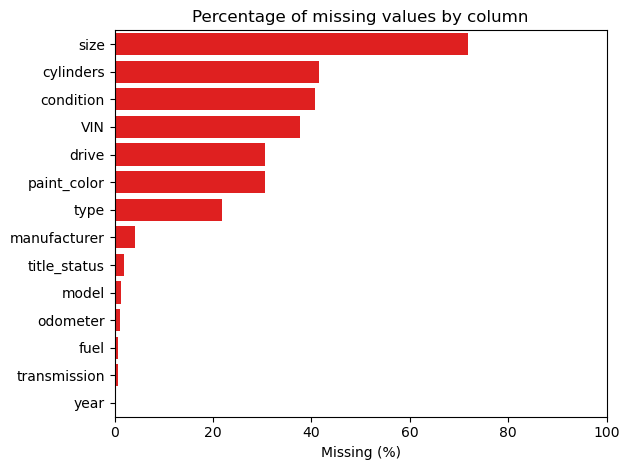

In [6]:
# Visualize missing data for each column
print(missing)
sns.barplot(x=missing.values/len(cars)*100, y=missing.index, color="red")
plt.title("Percentage of missing values by column")
plt.xlabel("Missing (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


Let's evaluate `price`, our target feature

count         426,880.00
mean           75,199.03
std        12,182,282.17
min                 0.00
1%                  0.00
5%                  0.00
25%             5,900.00
50%            13,950.00
75%            26,485.75
95%            44,500.00
99%            66,995.00
99.9%         120,000.00
max     3,736,928,711.00


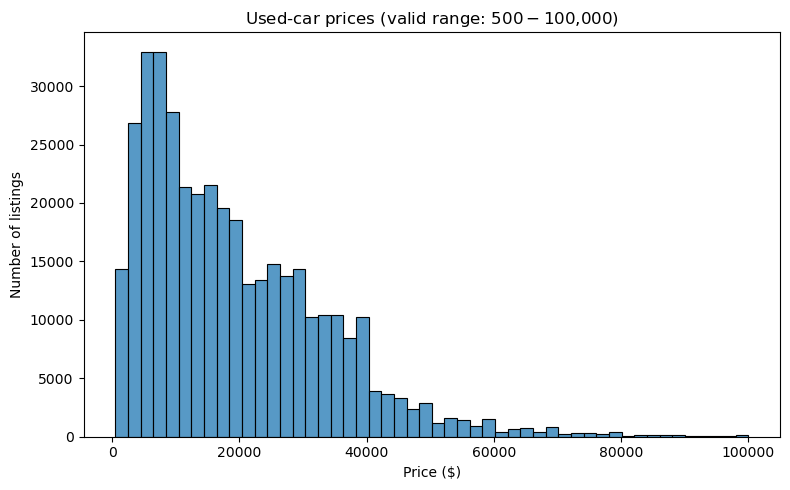

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Describe the price and visualize the distribution
price_summary = cars["price"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
)
# Print the price summary in standard format with two decimal places and commas for thousands
print(price_summary.to_string(float_format=lambda x: f"{x:,.2f}"))

# Trim outliers for visualization (aligned lower bound to $500 to match the plot title)
valid_prices = cars.loc[cars["price"].between(500, 100_000), "price"]

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the distribution of used-car prices
sns.histplot(valid_prices, bins=50, ax=ax)
ax.set_title("Used-car prices (valid range: $500-$100,000)")
ax.set_xlabel("Price ($)")
ax.set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

We can see the data is right skewed even after cutting off the most extreme outliers (<500 & >100000)


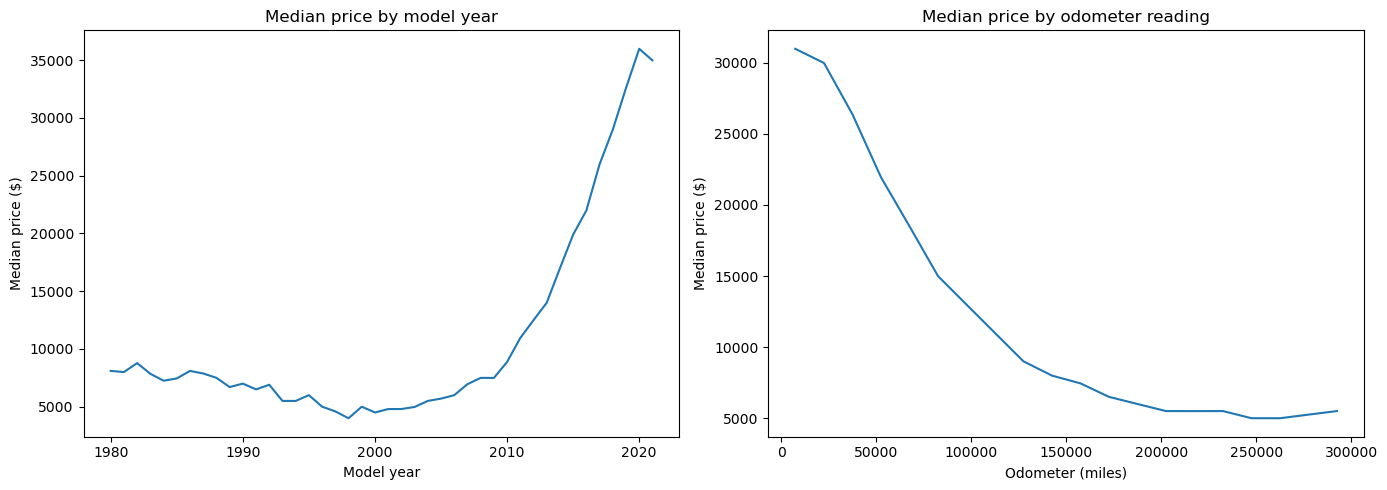

In [8]:
# plot the relationship between price and year and the price and odometer
plot_df = cars.loc[
    cars["price"].between(500, 100_000)
    & cars["year"].between(1980, 2022)
    & cars["odometer"].between(0, 300_000)
].copy()
plot_df["car_age"] = (2022 - plot_df["year"])

# Median price by model year, keeping only years with at least 100 listings
year_price = plot_df.groupby("year")["price"].agg(["median", "count"]).reset_index()
year_price = year_price[year_price["count"] >= 100]

# Median price by odometer range
plot_df["odometer_bin"] = pd.cut(plot_df["odometer"], bins=20)
odo_price = plot_df.groupby("odometer_bin", observed=True)["price"].median().reset_index()
odo_price["odometer_mid"] = odo_price["odometer_bin"].apply(lambda interval: interval.mid)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=year_price, x="year", y="median", ax=axes[0])
axes[0].set_title("Median price by model year")
axes[0].set_xlabel("Model year")
axes[0].set_ylabel("Median price ($)")

sns.lineplot(data=odo_price, x="odometer_mid", y="price", ax=axes[1])
axes[1].set_title("Median price by odometer reading")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Median price ($)")

plt.tight_layout()
plt.show()


Look at categorical features

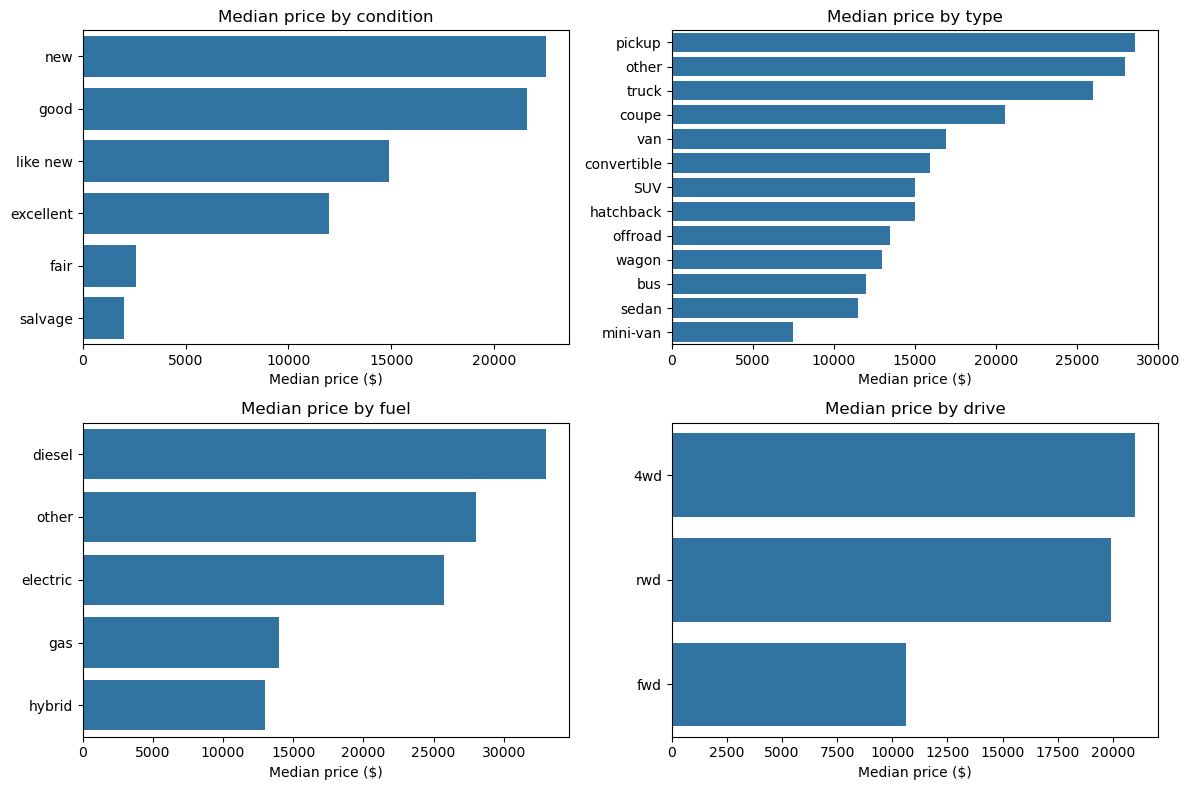

In [9]:
# setup subplots and make list of categories
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
category_columns = ["condition", "type", "fuel", "drive"]

#  Loop through each category and plot the median price
for ax, column in zip(axes.ravel(), category_columns):
    medians = plot_df.groupby(column)["price"].median().sort_values(ascending=False)
    sns.barplot(x=medians.values, y=medians.index, ax=ax)
    ax.set_title(f"Median price by {column}")
    ax.set_xlabel("Median price ($)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


In [10]:
# Look at manufacturers with the highest prices
manufacturer_stats = (
    plot_df.groupby("manufacturer")["price"]
    .agg(["median", "count"])
    .query("count >= 100")
    .sort_values("median", ascending=False)
)
manufacturer_view = pd.concat([manufacturer_stats.head(8), manufacturer_stats.tail(8)])
manufacturer_view.round(0)

,median,count
manufacturer,,
tesla,37990.0,833
ram,29999.0,15899
porsche,29950.0,1204
alfa-romeo,29590.0,823
jaguar,28990.0,1851
rover,25995.0,1893
audi,24990.0,6953
gmc,24590.0,14849
fiat,10900.0,735


And let's then look at heatmap of the correlation matrix for our numeric variables.

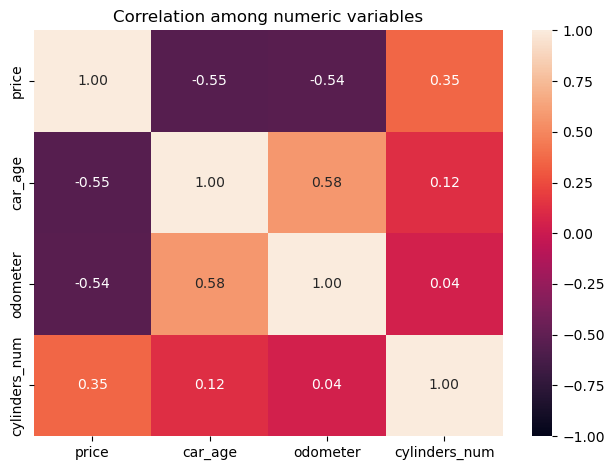

In [11]:
# first, convert cylinders to numeric 
plot_df["cylinders_num"] = pd.to_numeric(
    plot_df["cylinders"].astype(str).str.extract(r"(\d+)")[0]
)
numeric_corr = plot_df[["price", "car_age", "odometer", "cylinders_num"]].corr()

sns.heatmap(numeric_corr, annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation among numeric variables")
plt.tight_layout()
plt.show()

we see a corelation with price and the rest of the 3 features here, which is great. And we also see that car age and odometer are correlated as well which makes sense. Cylinders isn't correlated with age or adometer, which makes sense that they a independent. 

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

---

The cleaning and preparation steps are:

1. Keep listings with:
    - prices between **$100 and $100,000** 
    - model years from **1980 to 2022**
    - odometer readings up to **300,000 miles**. 
- This removes invalid entries and limits some outliers.
2. Drop useless columns: `id`, `VIN`, `region`, and `year` (will be replaced by `car_age`).
3. Engineer useful features: `car_age`, `car_age_squared`, `log_odometer`, `mileage_per_year`, and convert `cylinders` column to numeric.
4. Fill missing numbers with the median value, and fill missing categories with "unknown" and are categories are grouped with `low_freq=50` to keep the model manageable.

In [12]:
# Filter out implausible listings and show how many rows remain
cars_clean = cars.copy()
starting_rows = len(cars_clean)

cars_clean = cars_clean[cars_clean["price"].between(500, 100_000)]
cars_clean = cars_clean[cars_clean["year"].between(1980, 2022)]
cars_clean = cars_clean[cars_clean["odometer"].between(0, 300_000)]
cars_clean["year"] = cars_clean["year"].astype(int)

print(f"Rows before cleaning: {starting_rows:,}")
print(f"Rows after cleaning:  {len(cars_clean):,}")
print(f"Rows removed:         {starting_rows - len(cars_clean):,}")
cars_clean.head()


Rows before cleaning: 426,880
Rows after cleaning:  370,563
Rows removed:         56,317


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
27,7316814884,auburn,33590,2014,gmc,sierra 1500 crew cab slt,good,8 cylinders,gas,57923.0,clean,other,3GTP1VEC4EG551563,NaN,NaN,pickup,white,al
28,7316814758,auburn,22590,2010,chevrolet,silverado 1500,good,8 cylinders,gas,71229.0,clean,other,1GCSCSE06AZ123805,NaN,NaN,pickup,blue,al
29,7316814989,auburn,39590,2020,chevrolet,silverado 1500 crew,good,8 cylinders,gas,19160.0,clean,other,3GCPWCED5LG130317,NaN,NaN,pickup,red,al
30,7316743432,auburn,30990,2017,toyota,tundra double cab sr,good,8 cylinders,gas,41124.0,clean,other,5TFRM5F17HX120972,NaN,NaN,pickup,red,al
31,7316356412,auburn,15000,2013,ford,f-150 xlt,excellent,6 cylinders,gas,128000.0,clean,automatic,NaN,rwd,full-size,truck,black,al


In [13]:
# feature engineering and dropping useless columns
cars_clean["car_age"] = (2022 - cars_clean["year"])
cars_clean = cars_clean.drop(columns=["id", "VIN", "year", "region"])
# more features 
cars_clean["car_age_squared"] = cars_clean["car_age"] ** 2
cars_clean["log_odometer"] = np.log1p(cars_clean["odometer"])
cars_clean["mileage_per_year"] = cars_clean["odometer"] / cars_clean["car_age"].clip(lower=1)
cars_clean["cylinders"] = pd.to_numeric(
    cars_clean["cylinders"].astype(str).str.extract(r"(\d+)")[0]
)

display(cars_clean[["price", "car_age", "car_age_squared", "odometer", "log_odometer","mileage_per_year", "cylinders"]].head())


,price,car_age,car_age_squared,odometer,log_odometer,mileage_per_year,cylinders
27,33590,8,64,57923.0,10.966887,7240.375000,8.0
28,22590,12,144,71229.0,11.173669,5935.750000,8.0
29,39590,2,4,19160.0,9.860632,9580.000000,8.0
30,30990,5,25,41124.0,10.624371,8224.800000,8.0
31,15000,9,81,128000.0,11.759793,14222.222222,6.0


In [14]:
cars_clean.head(5)

,price,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color,state,car_age,car_age_squared,log_odometer,mileage_per_year
27,33590,gmc,sierra 1500 crew cab slt,good,8.0,gas,57923.0,clean,other,NaN,NaN,pickup,white,al,8,64,10.966887,7240.375000
28,22590,chevrolet,silverado 1500,good,8.0,gas,71229.0,clean,other,NaN,NaN,pickup,blue,al,12,144,11.173669,5935.750000
29,39590,chevrolet,silverado 1500 crew,good,8.0,gas,19160.0,clean,other,NaN,NaN,pickup,red,al,2,4,9.860632,9580.000000
30,30990,toyota,tundra double cab sr,good,8.0,gas,41124.0,clean,other,NaN,NaN,pickup,red,al,5,25,10.624371,8224.800000
31,15000,ford,f-150 xlt,excellent,6.0,gas,128000.0,clean,automatic,rwd,full-size,truck,black,al,9,81,11.759793,14222.222222


Make a list for numerical and one for categorical. We are then filling NaN or missing values then scaling & one-hot encoding.

In [15]:
numeric_features = [
    "car_age",
    "car_age_squared",
    "odometer",
    "log_odometer",
    "mileage_per_year",
    "cylinders",
]
categorical_features = [
    "manufacturer",
    "model",
    "condition",
    "fuel",
    "title_status",
    "transmission",
    "drive",
    "type",
    "paint_color",
    "size",
    "state",
]

# set missing numeric to median values
for col in numeric_features:
    median_val = cars_clean[col].median()
    cars_clean[col] = cars_clean[col].fillna(median_val)

# set missing categorical to "unknown" and group low-frequency categories into "other"
low_freq = 50

for col in categorical_features:
    # Fill missing with "unknown" first
    cars_clean[col] = cars_clean[col].fillna("unknown")
    
    # Get value counts
    counts = cars_clean[col].value_counts()
    
    # Identify low frequency categories OR are are "unknown"
    frequent_cats = set(counts[counts >= low_freq].index)
    frequent_cats.add("unknown")
    
    # Vectorized mask proved much faster than iterating through rows
    is_frequent = cars_clean[col].isin(frequent_cats)
    cars_clean.loc[~is_frequent, col] = "other"


print(f"Missing values after cleaning: {cars_clean.isna().sum().sum()}")

Missing values after cleaning: 0


### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

---
We will compare four regression approaches:

- **Baseline** — predicts average log price for every car
- **Ordinary least squares (OLS)** — standard linear regression
- **Ridge regression** — adds L2 regularization to reduce overfitting and stabilize coefficients.
- **Lasso regression** — adds L1 regularization and can shrink weak coefficients toward zero. Its penalty is tuned on a 50,000-row sample for speed and then refit on the full training set.

The target is `log(1 + price)` because our car prices are right skewed. 

Our evaluation metric is **root mean squared error (RMSE)**. 

We will also report **mean absolute error in dollars** because it is easier interpret for our client.


In [16]:
# Separate features
X = cars_clean.drop(columns="price")
y = np.log1p(cars_clean["price"])

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# scale numeric features, fit and transform
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

# One-hot encode categorical features, fit and 
combined = pd.concat([X_train, X_test], keys = ("train", "test"))
combined_encoded = pd.get_dummies(combined, columns=categorical_features, drop_first=True)

X_train = combined_encoded.xs("train")
X_test = combined_encoded.xs("test")

Fit, train, and evaluate models

In [17]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    
    # Predict on log scale
    y_pred_log = model.predict(X_te)
    log_rmse = np.sqrt(mean_squared_error(y_te, y_pred_log))
    
    # Convert back to real dollars for business interpretation
    y_pred_dollars = np.expm1(y_pred_log)
    y_true_dollars = np.expm1(y_te)
    dollar_mae = mean_absolute_error(y_true_dollars, y_pred_dollars)
    
    print(f"RMSE: {log_rmse:.4f}")
    print(f"Dollar-Scale MAE: ${dollar_mae:,.2f}\n")
    
    return model, log_rmse, dollar_mae

# Baseline
print("Baseline (mean):")
baseline = DummyRegressor(strategy="mean")
evaluate_model(baseline, X_train, y_train, X_test, y_test)

# Ordinary Least Squares (OLS)
print("OLS:")
ols = LinearRegression()
evaluate_model(ols, X_train, y_train, X_test, y_test)

# Ridge Regression
print("Ridge Regression:")
ridge = Ridge(alpha=10.0)
evaluate_model(ridge, X_train, y_train, X_test, y_test)

# Lasso Regression
print("Lasso on 50k row sample:")
sample_size = min(50_000, X_train.shape[0])
X_train_sample = X_train.sample(n=sample_size, random_state=42)
y_train_sample = y_train.loc[X_train_sample.index]

lasso = Lasso(alpha=0.0001, max_iter=2000, random_state=42)
evaluate_model(lasso, X_train_sample, y_train_sample, X_test, y_test)

Baseline (mean):
RMSE: 0.9000
Dollar-Scale MAE: $11,234.18

OLS:
RMSE: 0.4902
Dollar-Scale MAE: $4,260.87

Ridge Regression:
RMSE: 0.4904
Dollar-Scale MAE: $4,269.65

Lasso on 50k row sample:
RMSE: 0.5031
Dollar-Scale MAE: $4,671.80



(Lasso(alpha=0.0001, max_iter=2000, random_state=42),
 np.float64(0.5031264535357352),
 4671.802180218703)

**Cross Validate Results**

Ridge regression seems the better model so far but we should still cross validate, we will use 3-fold cross-validation.

In [18]:
# Take a quick 50k sample of training data so it runs faster
X_train_cv = X_train.sample(n=50000, random_state=42)
y_train_cv = y_train.loc[X_train_cv.index]

models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=0.0001, max_iter=1000, random_state=42)
}

print("Running Cross-Validation:\n")
for name, model in models.items():
    scores = cross_val_score(model, X_train_cv, y_train_cv, cv=3, scoring="neg_root_mean_squared_error")
    mean_rmse = abs(scores.mean())
    
    print(f"Model: {name}")
    print(f"Average Error (Log-RMSE): {mean_rmse:.3f}\n")

Running Cross-Validation:

Model: OLS
Average Error (Log-RMSE): 0.489

Model: Ridge
Average Error (Log-RMSE): 0.492

Model: Lasso
Average Error (Log-RMSE): 0.498



Again, Ridge wins out against Lasso but still slightly behind OLS. However, due to features being heavily correlated, I will stick to Ridge for our model

Let's use GridSearchSV to find the best alpha, again using Cross-validation

In [24]:
alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]

ridge_cv = RidgeCV(alphas=alphas, scoring='neg_root_mean_squared_error')
ridge_cv.fit(X_train_cv, y_train_cv)

print(f"Best Alpha found: {ridge_cv.alpha_}")

Best Alpha found: 1.0


In [23]:
evaluate_model(ridge_cv, X_train, y_train, X_test, y_test)

RMSE: 0.4902
Dollar-Scale MAE: $4,260.59



(RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 50.0, 100.0],
         scoring='neg_root_mean_squared_error'),
 np.float64(0.4901744444781678),
 4260.594627341446)

 Next up, we should visualize how well our model performed on the test data

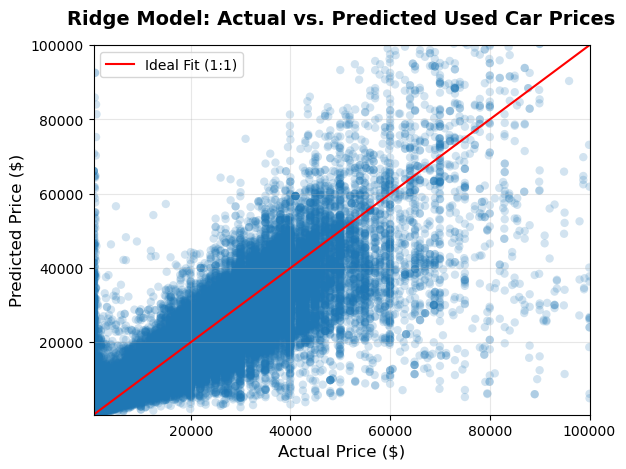

In [20]:
y_pred_log = ridge_cv.predict(X_test)

# Convert log values back to real dollar amounts for business interpretation
y_true_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred_log)

# scatter plot
plt.scatter(y_true_dollars, y_pred_dollars, alpha=0.2, edgecolors="none")

max_val = 100000  # upper price bound
min_val = 500  # Lower price bound 
# line
plt.plot([min_val, max_val], [min_val, max_val], color="red", label="Ideal Fit (1:1)")

# Labels
plt.title("Ridge Model: Actual vs. Predicted Used Car Prices", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Actual Price ($)", fontsize=12)
plt.ylabel("Predicted Price ($)", fontsize=12)

# bound the graph
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.legend(frameon=True, facecolor="white")
plt.grid(True, alpha=0.3)
plt.savefig('images/RidgeModel.png')
plt.show()

Above we can see that in the normal price range for used cars, around the `$5000 - $50,000` the model performed decently, with error increasing as the actual price goes up. Aditionally, not all of our outliers are gone, with strong peaks in the lower actual price.    

### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

---
The tuned Ridge model performs much better than the mean baseline. Cross validation RMSE is close to our test RMSE, so the model is not overfit. 

Our primary metric is **RMSE on log(1 + price)** because price is right-skewed and having just a few very expensive cars would dominate the error. 
- This tells that our model's predictions typically land within a margin of about about 49% of the car's actual listing price.  
- RMSE penalizes large misses, which is appropriate for pricing risk. 

The dollar MAE is included as a business-friendly secondary metric.
- Our MAE tells u s that on average, when the model predicts a car's price, its guess is off by about `$4,269.65` dollars
- This is a better technical understanding


We can now go back to our business objective and provide insight into what are leaders in driving the price to consumers.

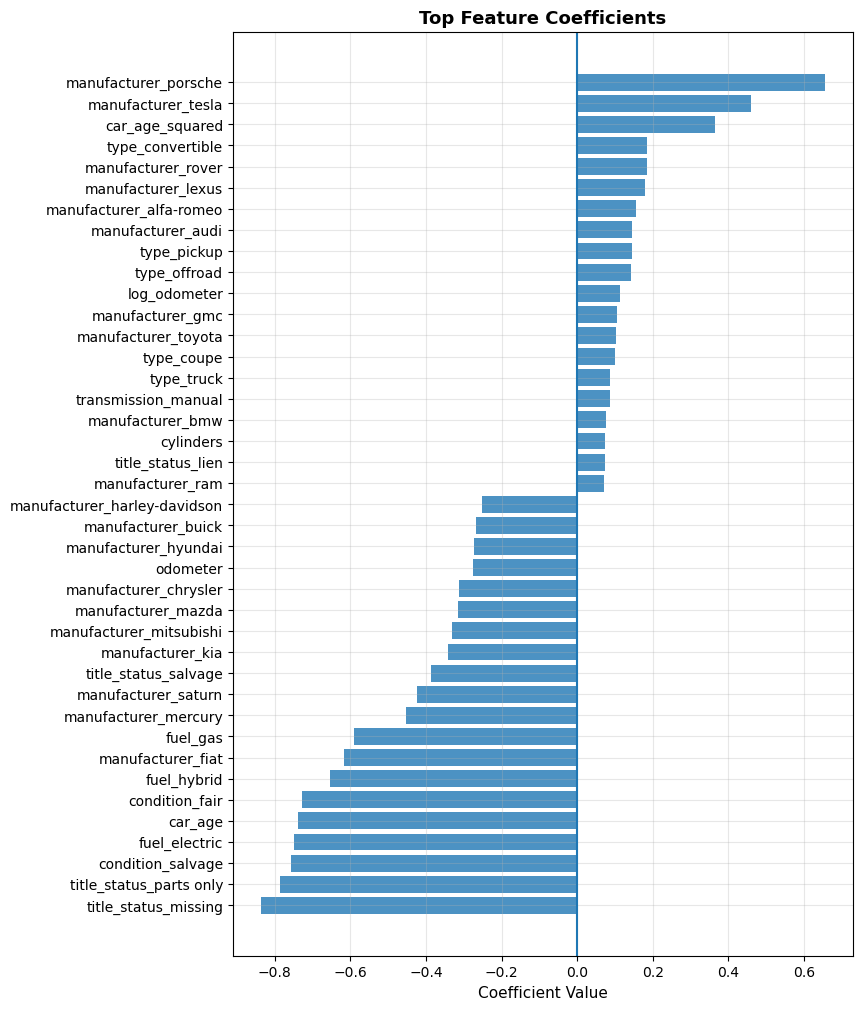

In [21]:
# Filter out features containing 'model' or 'other' or 'unkown'
filtered_items = [
    (name, coef) for name, coef in zip(X_train.columns, ridge_cv.coef_)
    if not any(term in name.lower() for term in ['model', 'other', 'unknown'])
]

num_coef = 20
filtered_items.sort(key=lambda x: x[1])
top_features = filtered_items[:num_coef] + filtered_items[-num_coef:]

names, coefs = zip(*top_features)

plt.figure(figsize=(8, 12))

plt.barh(names, coefs, alpha=0.8)
plt.axvline(0)

plt.title("Top Feature Coefficients", fontsize=13, fontweight="bold")
plt.xlabel("Coefficient Value", fontsize=11)
plt.grid(True, alpha=0.3)
plt.savefig('images/TopCoef.png')
plt.show()

Above we get data on the top feature coefficients that drive price up for consumers and what drives it lower. 

### Deployment
Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

---
#### What the analysis found

The tuned Ridge model beats the mean-price baseline. The typical dollar error is roughly **$4,260**. For our client, this model is useful as a sanity check and for relative pricing, but not a substitute for real appraisal.

1. **Age and mileage are consistent price depressors.** Though it's to be noted that with car_age_squared, eventually depreciation stops and classic cars can increase value.
2. **Condition and title status depress price** the worse the car's condition and title status the penalty to the cars value is significant. 
3. **Brands matter** Luxury brands as Porche, Tesla, Rover, and Alpha Romeo drive up the price, whereas budget brands such as Mitsubishi, Hyundai, and Kia drive down the price. There are some interesting notes about brands such as toyota which aren't typically considered a luxery brand, however it drives prices up which could be due to reliability.
4. **offroad, pickup, and convertable drive prices** Offroad and pickup are more expensive than other types most likely because of the utility they provide and the mechanics needed for that could drive up the base price. Convertables are associated with sports cars which are close to luxery, so it makes sense to drive the price.

#### What dealership should do to get the best priced cars

- **Stock late-model, low-mileage, clean-title vehicles.** These are the variables with the most reliable price drivers. So a dealership should look for vehicles with clean titles and excellent/good condition.

- **Stock high-demand body styles and models.** Pickups, trucks, SUVs, convertibles hold value better than economy style vehicles.

- **Treat salvage, fair, and parts-only vehicles as discount inventory.** The model estimates large price penalties for these vehicles, so only buy for low value and low volume to sell to more budget friendly buyers.
- - Also note that some of the cars will not have a title or condition label that accurately reflects the severity of the issues that could decrease price, so only buy much lower because of the risk.  

- **Use the model as sanity check, not to appraise vehicles** The model explains about 49% of price variation with a typical error of roughly $4,260. So you can use it to flag overpriced or underpriced listings, then confirm with condition, service history, and local market checks.
